In [10]:
import numpy as np
import xarray as xr
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from metpy.calc import geospatial_gradient, divergence
from scipy.stats import gaussian_kde
import metpy.constants as constants
from metpy.units import units
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geocat.viz as gv

In [11]:
basepts = [5, 3, 1]

# Selections:
level = [850,600]
stormTracks = ['N', 'N', 'O', 'NJ'],['S', 'S', 'O', 'SJ']
Ltitle = ['Northern Track', 'Northern Track', 'Northern Track'], ['Southern Track', 'Southern Track', 'Southern Track']
    
deltaLon = 15

label = ['(a) ','(b) ','(c) '], ['(d) ','(e) ','(f) ']


In [12]:
# def lat_lon_bounds(stormTrack, lonRef, latRef, deltaLon):
    
#     if (stormTrack == 'N'):
#         latS = 19.
#         latN = 23.
#     if (stormTrack == 'S' ):
#         latS = 7.
#         latN = 9.
#     if (stormTrack == 'O' ):
#         latS = 11.
#         latN = 13.

#     lonW = lonRef - deltaLon
#     lonE = lonRef + deltaLon
#     return latS, latN, lonW, lonE

def lat_lon_bounds(stormTrack, lonRef, latRef, deltaLon):
    
    if (stormTrack == 'N'):
        latS = 15.
        latN = 25.
    if (stormTrack == 'S' ):
        latS = 5.
        latN = 25.
    if (stormTrack == 'O' ):
        latS = 5.
        latN = 25.
    if (stormTrack == 'SJ'): #South of the jet
        latS = 5.
        latN = 12.
    if (stormTrack == 'NJ'): #North of the jet
        latS = 14.
        latN = 25.

    lonW = lonRef - deltaLon
    lonE = lonRef + deltaLon
    return latS, latN, lonW, lonE


In [4]:
# basepts = [5, 3, 1]

# # Selections:
# level = [850,600]
# stormTracks = ['N', 'N', 'O'],['S', 'S', 'O']
# Ltitle = ['Northern Track', 'Northern Track', 'Northern Track'], ['Southern Track', 'Southern Track', 'Southern Track']
    

# label = ['(a) ','(b) ','(c) '], ['(d) ','(e) ','(f) ']

# deltaLon = 1.5
# deltaLat = 1.5

# def lat_lon_bounds(stormTrack, lonRef, latRef, deltaLon):
#     latS = latRef-deltaLat
#     latN = latRef+deltaLat
#     lonW = lonRef - deltaLon
#     lonE = lonRef + deltaLon
#     return latS, latN, lonW, lonE

In [5]:
plotsdir = '/glade/u/home/athornton/plots/mm_criteria/' # save figure in this location

variables = ['mse_vint', 'dse_vint', 'q_vint', 
             'u', 'v', 'Q_prime', 
             'slhf', 'sshf', 'cp',
             'qp_vint_tend',
             'DSE_flux_div_vint']
varNames = ['mse_vint_prime', 'dse_vint_prime', 'q_vint_prime', 
            'U_prime', 'V_prime', 'Q_prime', 
            'SLHF_prime', 'SSHF_prime', 'CP_prime',
            'qp_vint_tend_prime',
            'DSE_flux_div_vint_prime']

In [6]:
# FUNCTION TO RETRIEVE DATA
def get_data(variab, level, basept, varNam):
    if variab in ['DSE_flux_div_vint']: # u and v have slightly different naming 
        ds = xr.open_dataset(data_path1+variab+'_Lag_Composite_RefV_'+str(level)+'hPa_track_point_'+str(basept)+'.nc')
    else:
        ds = xr.open_dataset(data_path2+variab+'_Lag_Composite_RefV_'+str(level)+'hPa_track_point_'+str(basept)+'.nc')
    lonRef = ds.Reflon.values
    latRef = ds.Reflat.values
    # var = ds[varNam].sel(latitude=slice(latRef+deltaLat, latRef-deltaLat), 
    #                                 longitude=slice(lonRef-deltaLon, lonRef+deltaLon), Lag=0).metpy.quantify()

    latS,latN,lonW,lonE = lat_lon_bounds(stormTrack,lonRef,latRef,deltaLon)
    var = ds[varNam].sel(latitude=slice(latN, latS), longitude=slice(lonW, lonE), Lag=0).metpy.quantify()
    
    var.attrs['lonRef'] = lonRef
    var.attrs['latRef'] = latRef
    return var

In [7]:
# LINEAR REGRESSION FUNCTION
def lin_reg(x,y):
    x = np.array(x)
    y = np.array(y)
    x_new = x.reshape(-1,1) # has to be one dimensional
    y_new = y.reshape(-1,1) # has to be one dimensional
    model = LinearRegression()
    model.fit(x_new,y_new)
    r_sq = model.score(x_new,y_new)
    m = model.coef_[0][0]
    
    ax[i,j].plot(x_new, model.predict(x_new),color='k')
    return r_sq, m

In [8]:
# INSET MAP FUNCTION
def inset_map():
    inset_ax = inset_axes(ax[i,j],
                    width="18%", # width = 30% of parent_bbox
                    height=0.65, # height : 1 inch
                    loc=2, 
                    axes_class=cartopy.mpl.geoaxes.GeoAxes,
                    axes_kwargs=dict(map_projection=ccrs.PlateCarree()))
    minlon = lonRef - 30.
    maxlon = lonRef + 30.
    minlat = -5.
    maxlat = 30.

    #Set the extent or specific region for the inset map
    inset_ax.set_extent([minlon, maxlon, minlat, maxlat])  

    #Add coastlines and other features to the inset map
    inset_ax.add_feature(cfeature.COASTLINE, zorder=1)
    inset_ax.plot(lonRef, latRef, marker='o', markersize=5, color='red', transform=ccrs.PlateCarree())

FileNotFoundError: [Errno 2] No such file or directory: '/glade/derecho/scratch/athornton/era5_temp/dse_flux_div/DSE_flux_div_vint_Lag_Composite_RefV_850hPa_track_point_5.nc'

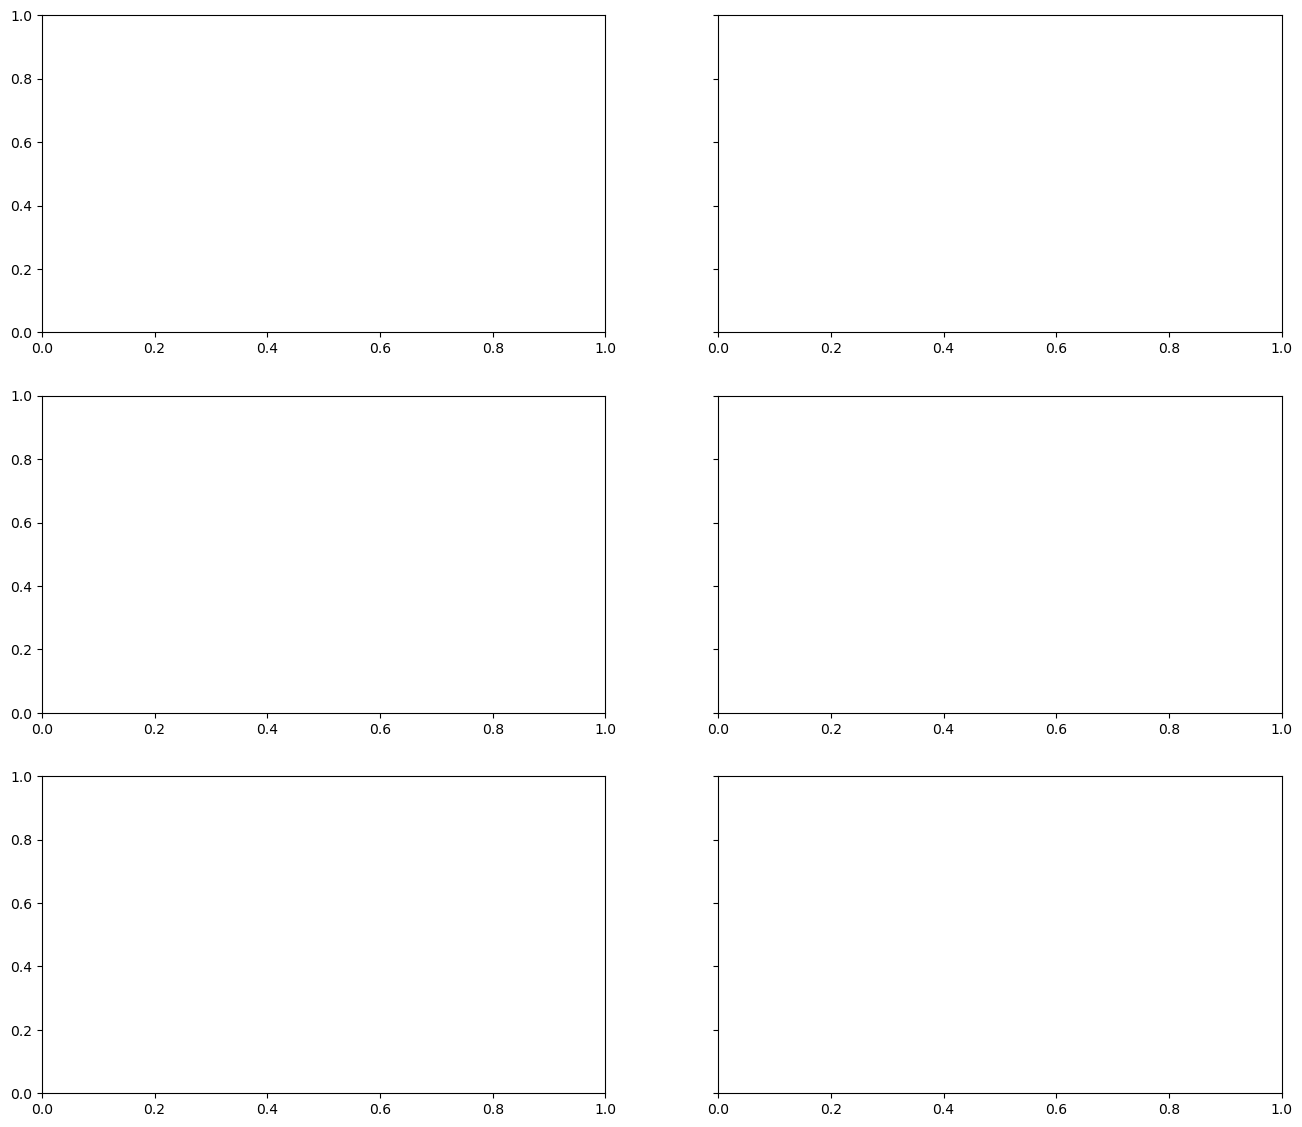

In [9]:
# Generate figure (set its size (width, height) in inches) and axes
fig, ax = plt.subplots(3,2, figsize=(16, 14), sharey=True)  # Share y-axis for consistency

plt.rcParams['savefig.dpi'] = 255 # Set image quality

#for i in reversed(range(0,6)): # plot from land to ocean
for j in range (0,2): # loop through levels
    for i in range(0, 3): # loop through basepoints
        data_path1 = '/glade/derecho/scratch/athornton/era5_temp/dse_flux_div/'
        data_path2 = '/glade/derecho/scratch/aiyyer/mse/composites/refV' + str(level[j]) + '/'
        stormTrack=stormTracks[j][i]
        dse = get_data(variables[10], level[j], basepts[i], varNames[10])
        print(level[j])
        print(basepts[i])
        print(stormTrack)
        Q   = get_data(variables[5], level[j], basepts[i], varNames[5]) 
        sh  = get_data(variables[7], level[j], basepts[i], varNames[7])
        cp  = get_data(variables[8], level[j], basepts[i], varNames[8]) 
        precip = cp*constants.density_water*constants.water_heat_vaporization
        precip = precip.metpy.convert_units('watts/(m**2)')
        lonRef = dse.lonRef
        latRef = dse.latRef


        heating = Q + precip + sh  # heating
        
        ax[i,j].scatter(dse, heating, facecolor='darkcyan', alpha=0.15)
        ax[i,j].set_xlim(-500, 500)
        
        # For points south of the jet
        stormTrack=stormTracks[j][3]        
        dse_south = get_data(variables[10], level[j], basepts[i], varNames[10])
        Q_s   = get_data(variables[5], level[j], basepts[i], varNames[5]) 
        sh_s  = get_data(variables[7], level[j], basepts[i], varNames[7])
        cp_s  = get_data(variables[8], level[j], basepts[i], varNames[8]) 
        precip_s = cp_s*constants.density_water*constants.water_heat_vaporization
        precip_s = precip_s.metpy.convert_units('watts/(m**2)')
        heating_south = Q_s + precip_s + sh_s
        
        #r_sq, m = lin_reg(dse_south, heating_south)
        r_sq, m = lin_reg(dse, heating) # linear regression function
        
        # Get existing legend handles and labels
        handles, labels = ax[i,j].get_legend_handles_labels()
        
        # Append R^2 value as a label without a handle
        labels.append(f'R² = {r_sq:.4f}')
        labels.append('slope = ' + str(m))
        
        handles.append(plt.Line2D([0], [0], linestyle="none"))  # Empty handle for text entry
        handles.append(plt.Line2D([1], [0], linestyle="none"))  # Empty handle for text entry
        
        # Set the legend with the updated handles and labels
        ax[i, j].legend(handles, labels, fontsize=14, loc='lower right', edgecolor='white')

        gv.set_titles_and_labels(ax[i,j],
                         lefttitle=label[j][i] +' '+ Ltitle[j][j],
                         righttitle='Lat = ' + str(dse.latRef) +', Lon = ' + str(dse.lonRef),                         
                         lefttitlefontsize=15,
                         righttitlefontsize=15,
                         labelfontsize=15)
        ax[i,0].set_ylabel('Heating ($W/m^2$)', fontsize=15)
        inset_map()

ax[2,0].set_xlabel('DSE Flux Divergence ($W/m^2$)', fontsize=15)
ax[2,1].set_xlabel('DSE Flux Divergence ($W/m^2$)', fontsize=15)
plt.tight_layout()
plt.suptitle('WTG Balance', weight='bold', fontsize=20, x=0.5,y=1.03) # main title
#plt.savefig(plotsdir+'dse_vs_heat_smaller.png')